# **Segmentation**

#### **1. Superpixels**

- Superpixels group pixels into perceptually meaningful atomic regions.

- SLIC (Simple Linear Iterative Clustering) produces compact, uniform superpixels.

- Useful as a preprocessing step to reduce complexity for segmentation or classification.

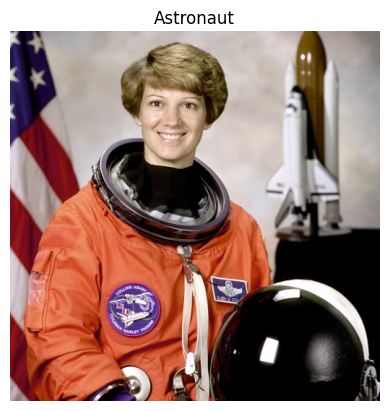

In [27]:
from skimage import data, segmentation
import matplotlib.pyplot as plt
import numpy as np

image = data.astronaut()

plt.imshow(image)
plt.title("Astronaut")
plt.axis('off')
plt.show()

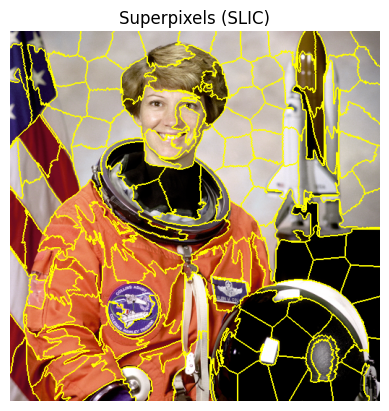

In [31]:

segments = segmentation.slic(image, n_segments=200, compactness=10, start_label=1)

plt.imshow(segmentation.mark_boundaries(image, segments))
plt.title("Superpixels (SLIC)")
plt.axis('off')
plt.show()

#### **2.Visualizing segmentation with Label2RGB**

- Visualizes labeled segments over the original image by coloring each segmented region with the average color of the corresponding pixels from the original image.

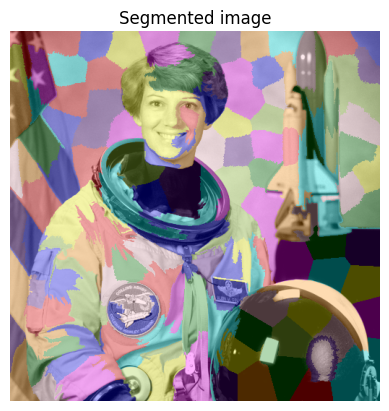

In [33]:
from skimage import color
from skimage.color import label2rgb

# segmented_image = label2rgb(segments, image, kind='avg')
segmented_image = label2rgb(segments, image, kind='overlay')

plt.imshow(segmented_image)
plt.title("Segmented image")
plt.axis('off')
plt.show()

#### **3. Segmenting regions and labeling**
- After thresholding or clustering, identify connected regions.
- Use `skimage.measure.label` to assign unique labels to connected components.

155


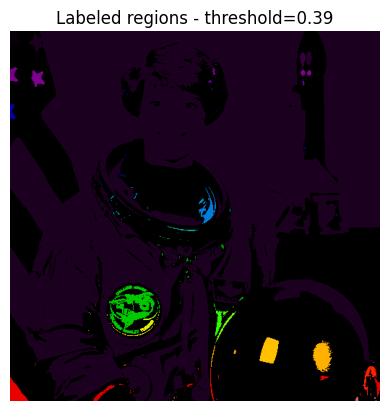

In [38]:
from skimage import measure, filters

gray = color.rgb2gray(image)
thresh = filters.threshold_otsu(gray)
binary = gray > thresh

labels = measure.label(binary)
print(labels.max())

plt.imshow(labels, cmap='nipy_spectral')
# plt.imshow(labels, cmap='viridis')
plt.title(f"Labeled regions - threshold={thresh:.2f}")
plt.axis('off')
plt.show()


#### **4. Contour detection**
- Extract contours (boundaries) of segmented objects.

- `skimage.measure.find_contours` finds continuous curves at specified intensity levels.


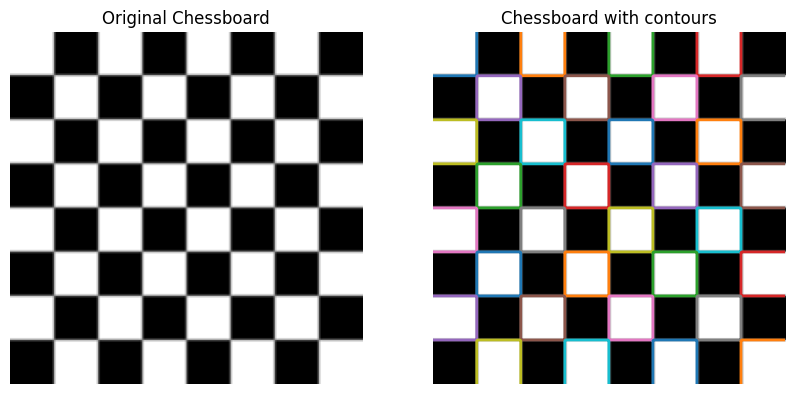

In [39]:
import matplotlib.pyplot as plt
from skimage import data, measure, filters

checkerboard = data.checkerboard()

T = filters.threshold_otsu(checkerboard)
T_checkerboard = checkerboard > T

contours = measure.find_contours(T_checkerboard, 0.5)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(checkerboard, cmap='gray')
plt.title('Original Chessboard')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(checkerboard, cmap='gray')
for contour in contours:
    plt.plot(contour[:, 1], contour[:, 0], linewidth=2)
plt.title('Chessboard with contours')
plt.axis('off')

plt.show()


#### **5. Corner detection using Harris detector**
- Detect corner points where edges meet.
- `corner_harris` computes Harris response, `corner_peaks` extracts corner coordinates.

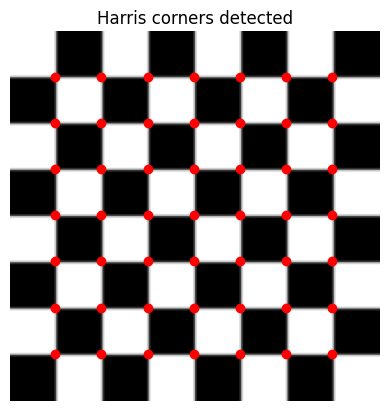

In [40]:
from skimage.feature import corner_harris, corner_peaks

harris_response = corner_harris(checkerboard)
coords = corner_peaks(harris_response, min_distance=10)

plt.imshow(checkerboard, cmap='gray')
plt.scatter(coords[:, 1], coords[:, 0], marker='o', color='red')
plt.title("Harris corners detected")
plt.axis('off')
plt.show()


#### **6. Flood fill segmentation**
Flood fill identifies a connected region around a seed where values are similar. Use `segmentation.flood` on grayscale or color channels for region-growing.

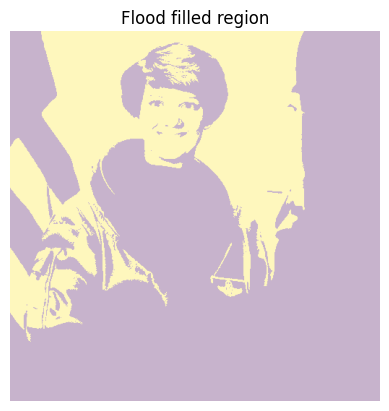

In [41]:
seed_point = (100, 220)
flood_mask = segmentation.flood(gray, seed_point, tolerance=0.3)

plt.imshow(flood_mask, alpha=0.3)
plt.title('Flood filled region')
plt.axis('off')
plt.show()

#### **7. Measuring object properties (regionprops)**

`skimage.measure.regionprops` allows measurement of geometric and intensity-based features from labeled regions. Typical properties: area, centroid, orientation, bounding box, mean intensity.

In [ ]:
%pip install pandas


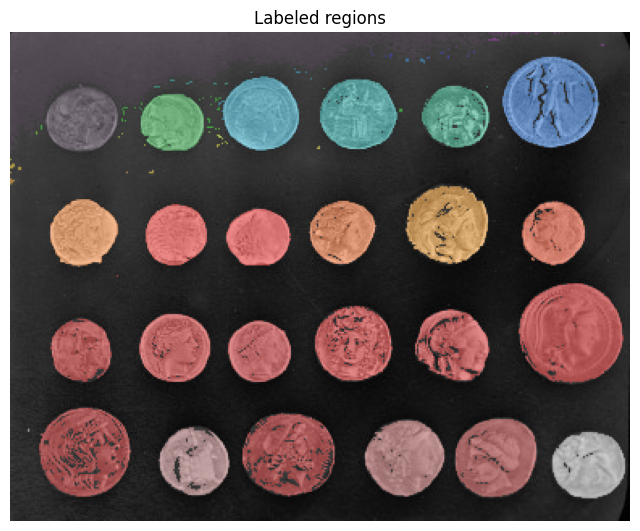

     area  centroid-0  centroid-1  orientation  eccentricity
0  8792.0   22.825296   90.538558    -1.423583      0.975705
1    37.0    1.081081  302.189189     1.524098      0.957465
2    21.0    0.380952  315.285714    -1.508404      0.992326
3     1.0    0.000000  328.000000    -0.785398      0.000000
4     2.0    0.500000  337.000000     0.000000      1.000000
5     2.0    0.000000  339.500000     1.570796      1.000000
6     1.0    0.000000  342.000000    -0.785398      0.000000
7     2.0    1.000000  325.500000     1.570796      1.000000
8     9.0    4.777778  299.111111    -1.542372      0.973119
9     2.0    8.000000  366.500000     1.570796      1.000000


In [45]:
import pandas as pd

coins = data.coins()

T = filters.threshold_otsu(coins)
binary = coins > T

labels = measure.label(binary)

plt.figure(figsize=(8, 8))
plt.imshow(coins, cmap='gray')
plt.imshow(labels, cmap='nipy_spectral', alpha=0.4)
plt.title('Labeled regions')
plt.axis('off')
plt.show()

props = measure.regionprops_table(
    labels,
    properties=['area', 'centroid', 'orientation', 'eccentricity']
)
props_df = pd.DataFrame(props)

print(props_df.head(10))
